In [1]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sb
import numpy as np

In [2]:
df = pd.read_csv('../datasets/vgsales.csv')

In [3]:
df

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37
...,...,...,...,...,...,...,...,...,...,...,...
16593,16596,Woody Woodpecker in Crazy Castle 5,GBA,2002.0,Platform,Kemco,0.01,0.00,0.00,0.00,0.01
16594,16597,Men in Black II: Alien Escape,GC,2003.0,Shooter,Infogrames,0.01,0.00,0.00,0.00,0.01
16595,16598,SCORE International Baja 1000: The Official Game,PS2,2008.0,Racing,Activision,0.00,0.00,0.00,0.00,0.01
16596,16599,Know How 2,DS,2010.0,Puzzle,7G//AMES,0.00,0.01,0.00,0.00,0.01


In [4]:
# Data Preparation

In [5]:
df.isnull().sum()

Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64

In [6]:
df.Year =df.Year.fillna(0)
df.Publisher = df.Publisher.fillna(0)

In [7]:
df.isnull().sum()

Rank            0
Name            0
Platform        0
Year            0
Genre           0
Publisher       0
NA_Sales        0
EU_Sales        0
JP_Sales        0
Other_Sales     0
Global_Sales    0
dtype: int64

In [8]:
df.dtypes

Rank              int64
Name             object
Platform         object
Year            float64
Genre            object
Publisher        object
NA_Sales        float64
EU_Sales        float64
JP_Sales        float64
Other_Sales     float64
Global_Sales    float64
dtype: object

In [9]:
# Exploratroy Data Analysis

In [10]:
df.describe()

,Rank,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,16598.000000,16598.000000,16598.000000,16598.000000,16598.000000,16598.000000,16598.000000
mean,8300.605254,1973.647307,0.264667,0.146652,0.077782,0.048063,0.537441
std,4791.853933,254.346809,0.816683,0.505351,0.309291,0.188588,1.555028
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.010000
25%,4151.250000,2003.000000,0.000000,0.000000,0.000000,0.000000,0.060000
50%,8300.500000,2007.000000,0.080000,0.020000,0.000000,0.010000,0.170000
75%,12449.750000,2010.000000,0.240000,0.110000,0.040000,0.040000,0.470000
max,16600.000000,2020.000000,41.490000,29.020000,10.220000,10.570000,82.740000


In [11]:
p = df.groupby('Platform')['Global_Sales'].agg(['sum','mean'])

In [12]:
p

,sum,mean
Platform,,
2600,97.08,0.729925
3DO,0.10,0.033333
3DS,247.46,0.486169
DC,15.97,0.307115
DS,822.49,0.380254
GB,255.45,2.606633
GBA,318.50,0.387470
GC,199.36,0.358561
GEN,28.36,1.050370


In [13]:
g = df.groupby('Genre')['Global_Sales'].agg(['sum','mean'])

In [14]:
g

,sum,mean
Genre,,
Action,1751.18,0.528100
Adventure,239.04,0.185879
Fighting,448.91,0.529375
Misc,809.96,0.465762
Platform,831.37,0.938341
Puzzle,244.95,0.420876
Racing,732.04,0.586101
Role-Playing,927.37,0.623233
Shooter,1037.37,0.791885


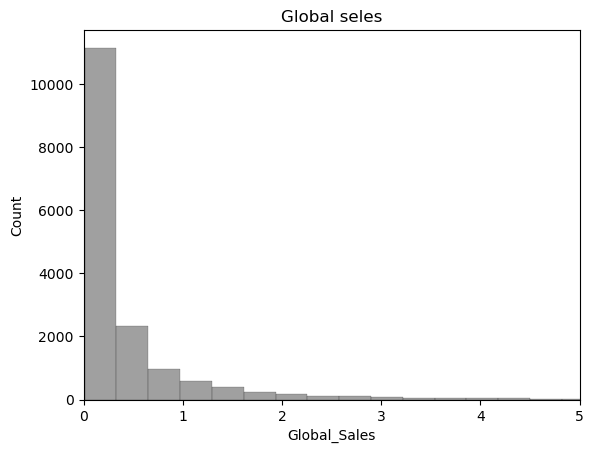

In [17]:
sb.histplot(df['Global_Sales'], color='grey')
plt.xlim(0,5)
plt.title('Global seles')
plt.show()

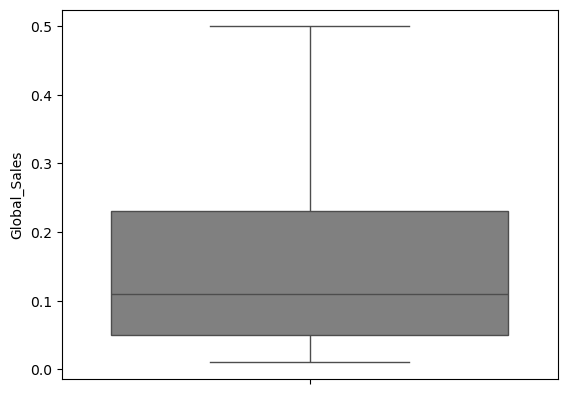

In [45]:
sb.boxplot(df['Global_Sales'],color='grey')
plt.show()

In [46]:
i ='Global_Sales'

q1 = np.percentile(df[i],25)
q3 = np.percentile(df[i],75)

iqr = q3-q1

c1 = q1-1.5*(iqr)
c2 = q3+1.5*(iqr)


In [47]:
t = df[(df[i]>c2) | (df[i]<c1)]
t=t.index
df=df.drop(labels=t)

In [48]:
t

Index([], dtype='int64')

In [49]:
# Top Selling Games Analysis

In [50]:
df.columns

Index(['Rank', 'Name', 'Platform', 'Year', 'Genre', 'Publisher', 'NA_Sales',
       'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales'],
      dtype='object')

In [51]:
df.sort_values('Global_Sales').count()

Rank            12651
Name            12651
Platform        12651
Year            12651
Genre           12651
Publisher       12651
NA_Sales        12651
EU_Sales        12651
JP_Sales        12651
Other_Sales     12651
Global_Sales    12651
dtype: int64

In [52]:
df.Global_Sales.sum()

np.float64(1900.2399999999998)

In [53]:
df.Name.value_counts(10)

Name
Angry Birds Star Wars         0.000632
Terraria                      0.000553
Major League Baseball 2K11    0.000553
Surf's Up                     0.000553
Skylanders: SuperChargers     0.000553
                                ...   
Summon Night: Twin Age        0.000079
Harvest Moon DS (jp sales)    0.000079
Grand Knights History         0.000079
Street Fighter IV             0.000079
Know How 2                    0.000079
Name: proportion, Length: 9539, dtype: float64

In [54]:
# Platform Perfomance Analysis

In [55]:
df.groupby('Platform')['Global_Sales'].sum()

Platform
2600     25.21
3DO       0.10
3DS      57.07
DC        6.61
DS      237.07
GB        7.92
GBA     102.92
GC       70.48
GEN       1.57
GG        0.04
N64      46.12
NES       2.35
NG        1.44
PC       66.35
PCFX      0.03
PS      146.11
PS2     272.95
PS3     146.20
PS4      30.22
PSP     118.42
PSV      39.58
SAT      24.86
SCD       0.37
SNES     34.55
TG16      0.16
WS        0.91
Wii     170.23
WiiU     17.67
X360    154.32
XB       96.68
XOne     21.73
Name: Global_Sales, dtype: float64

In [56]:
df.groupby(['Year','Platform'])['Global_Sales'].sum()

Year    Platform
0.0     2600        3.94
        3DS         1.18
        DS          2.18
        GBA         1.14
        GC          1.68
                    ... 
2016.0  X360        0.83
        XOne        4.48
2017.0  PS4         0.03
        PSV         0.02
2020.0  DS          0.29
Name: Global_Sales, Length: 242, dtype: float64

In [57]:
b = df.groupby('Platform')['Global_Sales'].sum()

In [58]:
b

Platform
2600     25.21
3DO       0.10
3DS      57.07
DC        6.61
DS      237.07
GB        7.92
GBA     102.92
GC       70.48
GEN       1.57
GG        0.04
N64      46.12
NES       2.35
NG        1.44
PC       66.35
PCFX      0.03
PS      146.11
PS2     272.95
PS3     146.20
PS4      30.22
PSP     118.42
PSV      39.58
SAT      24.86
SCD       0.37
SNES     34.55
TG16      0.16
WS        0.91
Wii     170.23
WiiU     17.67
X360    154.32
XB       96.68
XOne     21.73
Name: Global_Sales, dtype: float64

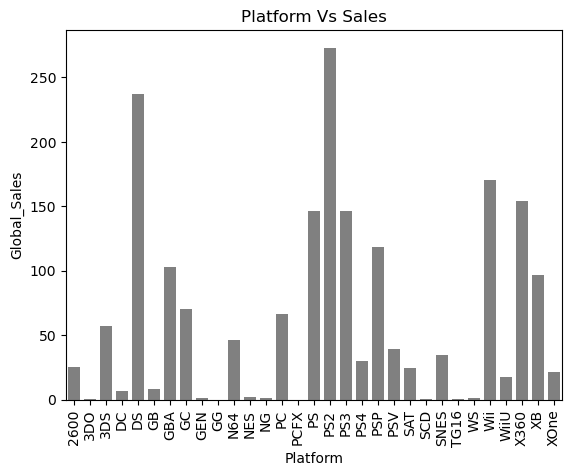

In [88]:
sb.barplot(b, color='grey')
plt.xticks(rotation=90)
plt.title('Platform Vs Sales')
plt.show()

In [60]:
# Genre Anallysis

In [61]:
df.groupby('Genre')['Global_Sales'].sum()

Genre
Action          407.19
Adventure       109.81
Fighting        101.29
Misc            210.46
Platform         96.32
Puzzle           57.43
Racing          145.89
Role-Playing    163.28
Shooter         137.95
Simulation      103.39
Sports          295.19
Strategy         72.04
Name: Global_Sales, dtype: float64

In [62]:
s = df.groupby('Global_Sales')['Genre'].max()

In [63]:
s

Global_Sales
0.01    Strategy
0.02    Strategy
0.03    Strategy
0.04    Strategy
0.05    Strategy
0.06    Strategy
0.07    Strategy
0.08    Strategy
0.09    Strategy
0.10    Strategy
0.11    Strategy
0.12    Strategy
0.13    Strategy
0.14    Strategy
0.15    Strategy
0.16    Strategy
0.17    Strategy
0.18    Strategy
0.19    Strategy
0.20    Strategy
0.21    Strategy
0.22    Strategy
0.23    Strategy
0.24    Strategy
0.25    Strategy
0.26    Strategy
0.27    Strategy
0.28    Strategy
0.29    Strategy
0.30    Strategy
0.31    Strategy
0.32    Strategy
0.33    Strategy
0.34    Strategy
0.35    Strategy
0.36    Strategy
0.37    Strategy
0.38    Strategy
0.39    Strategy
0.40    Strategy
0.41    Strategy
0.42    Strategy
0.43    Strategy
0.44    Strategy
0.45    Strategy
0.46    Strategy
0.47    Strategy
0.48    Strategy
0.49      Sports
0.50    Strategy
Name: Genre, dtype: object

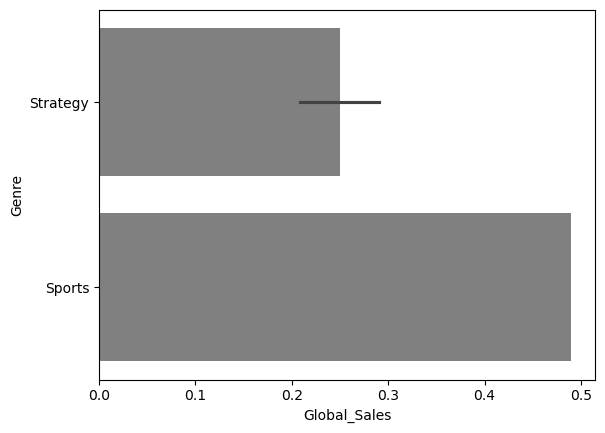

In [64]:
sb.barplot(s, color='grey')
plt.show()

In [65]:
Trends = df.groupby(['Year','Genre'])['Global_Sales'].sum().reset_index()

In [66]:
Trends

,Year,Genre,Global_Sales
0,0.0,Action,9.32
1,0.0,Adventure,0.55
2,0.0,Fighting,1.32
3,0.0,Misc,2.26
4,0.0,Platform,1.19
...,...,...,...
346,2016.0,Sports,3.53
347,2016.0,Strategy,0.50
348,2017.0,Action,0.01
349,2017.0,Role-Playing,0.04


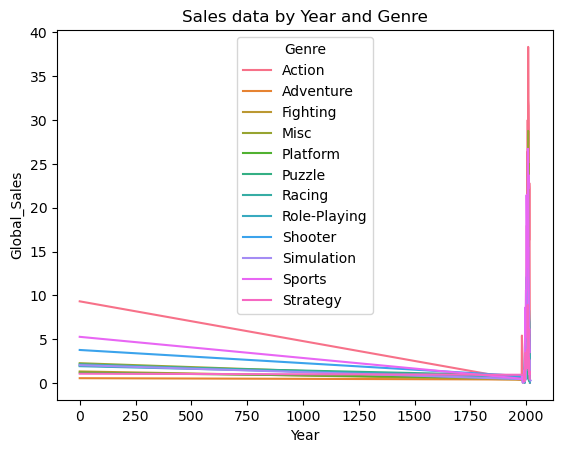

In [67]:
sb. lineplot (data=Trends, x= 'Year',y='Global_Sales' ,hue='Genre')
plt. title('Sales data by Year and Genre') 
plt. show()

In [68]:
# Publisher Performance Analysis 

In [69]:
top_performing = df.groupby('Publisher')['Global_Sales'].sum().nlargest(10).reset_index()

In [70]:
top_performing

,Publisher,Global_Sales
0,Electronic Arts,155.64
1,Activision,134.51
2,Ubisoft,114.86
3,Namco Bandai Games,112.32
4,THQ,109.59
5,Konami Digital Entertainment,107.16
6,Sega,82.49
7,Sony Computer Entertainment,79.67
8,Nintendo,58.29
9,Atari,48.08


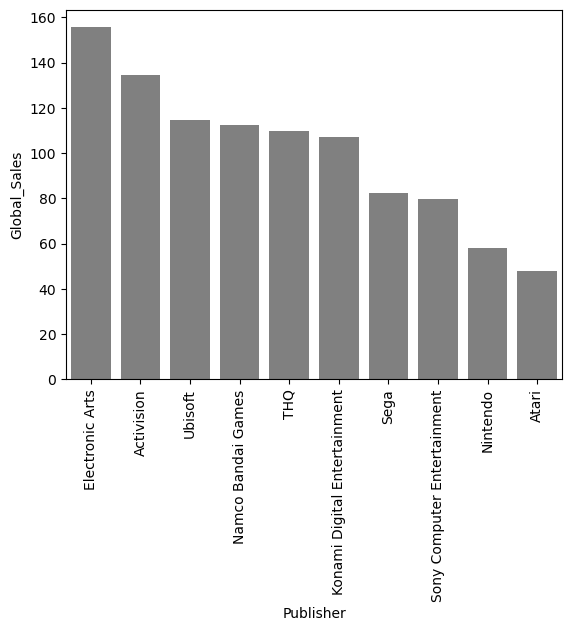

In [71]:
sb.barplot(top_performing, x='Publisher', y='Global_Sales',color='grey')
plt.xticks(rotation=90)
plt.show()

In [72]:
Publisher_Perfromance = df.groupby('Publisher')[['NA_Sales','EU_Sales','JP_Sales','Other_Sales']].sum(10)

In [73]:
Publisher_Perfromance

,NA_Sales,EU_Sales,JP_Sales,Other_Sales
Publisher,,,,
0,3.32,2.06,0.93,0.09
10TACLE Studios,0.07,0.04,0.00,0.00
1C Company,0.01,0.07,0.00,0.02
20th Century Fox Video Games,1.08,0.06,0.00,0.00
2D Boy,0.00,0.03,0.00,0.01
...,...,...,...,...
iWin,0.00,0.05,0.00,0.01
id Software,0.02,0.00,0.00,0.00
imageepoch Inc.,0.00,0.00,0.04,0.00


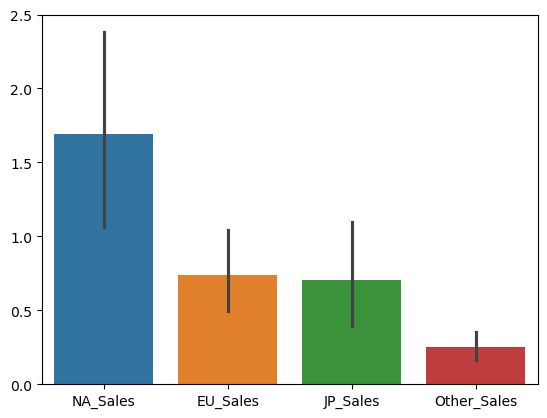

In [74]:
sb.barplot(Publisher_Perfromance)
plt.show()

In [75]:
# Regional Sales Analysis

In [76]:
# Aggregate data
region_sales = df[['NA_Sales','EU_Sales','JP_Sales','Other_Sales']].sum()

In [77]:
region_sales

NA_Sales       947.50
EU_Sales       413.31
JP_Sales       395.00
Other_Sales    140.04
dtype: float64

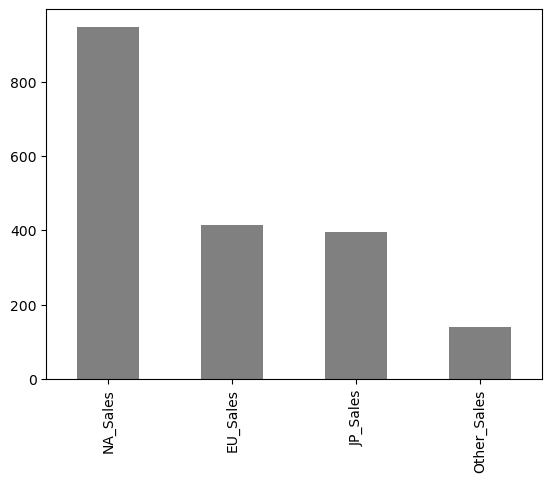

In [78]:
# Visualize Regional Sales
df[['NA_Sales','EU_Sales','JP_Sales','Other_Sales']].sum().plot(kind='bar',color='grey',stacked=True)
plt.show()

In [79]:
# Identify Region
n = df.sort_values(by='NA_Sales',ascending=False).head(10)
e = df.sort_values(by='EU_Sales',ascending=False).head(10)
j= df.sort_values(by='JP_Sales',ascending=False).head(10)
o = df.sort_values(by='Other_Sales',ascending=False).head(10)

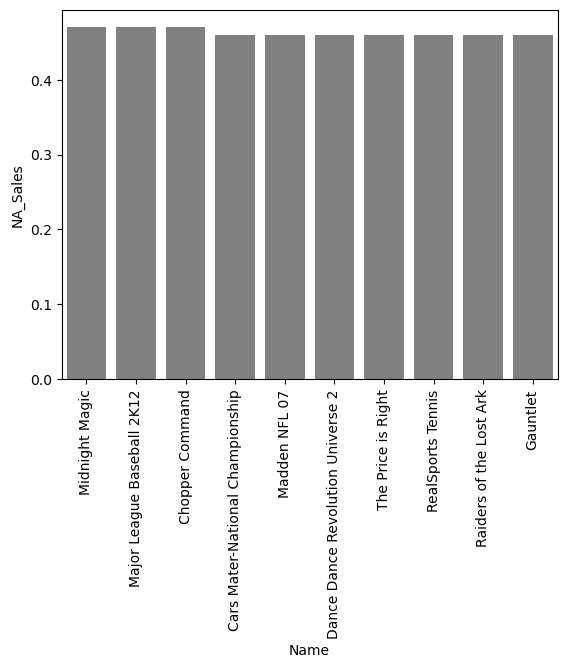

In [80]:
sb.barplot(n, x='Name', y='NA_Sales',color='grey')
plt.xticks(rotation=90)
plt.show()

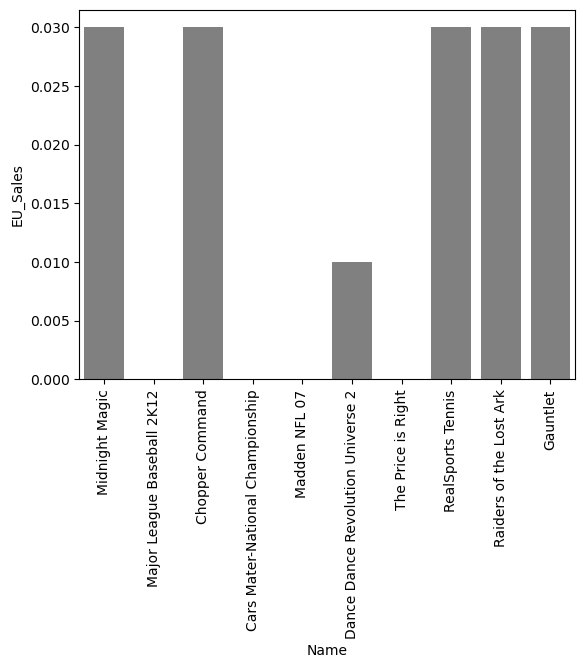

In [81]:
sb.barplot(n, x='Name', y='EU_Sales',color='grey')
plt.xticks(rotation=90)
plt.show()

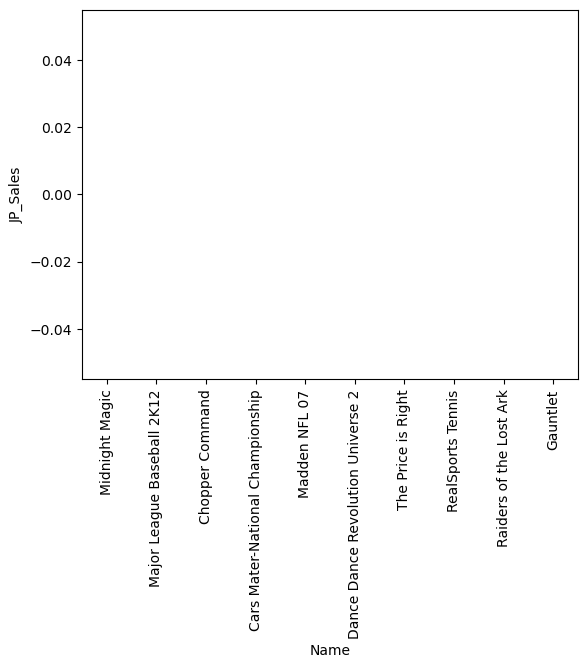

In [90]:
sb.barplot(n, x='Name', y='JP_Sales',color='grey')
plt.xticks(rotation=90)
plt.show()

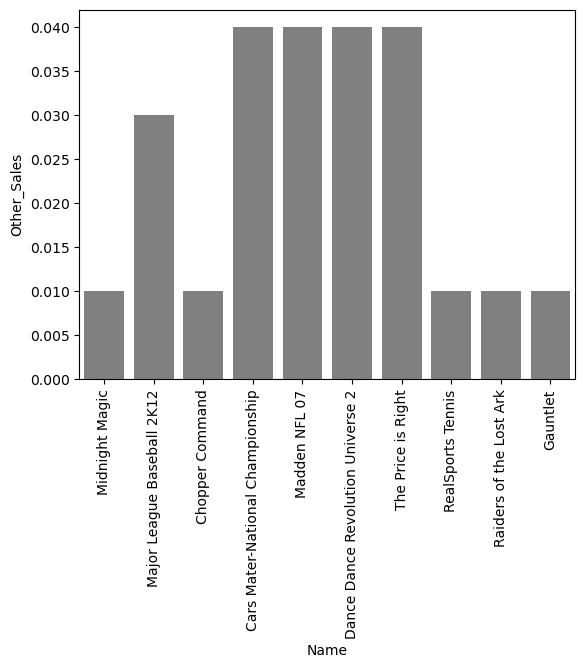

In [83]:
sb.barplot(n, x='Name', y='Other_Sales',color='grey')
plt.xticks(rotation=90)
plt.show()

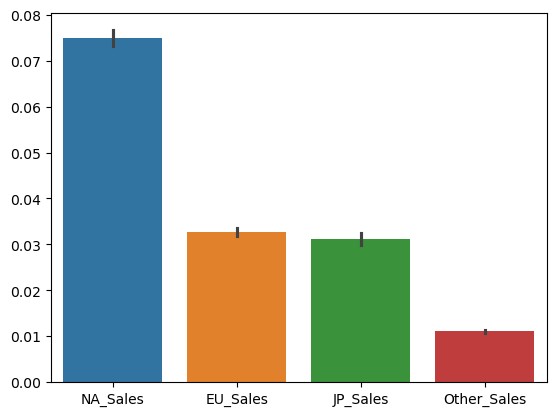

In [85]:
sb.barplot(df[['NA_Sales','EU_Sales','JP_Sales','Other_Sales']])
plt.show()